# Imports

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load Dataset

In [9]:
df = pd.read_csv("iris.csv")

X = df[[
    "sepal.length",
    "sepal.width",
    "petal.length",
    "petal.width"
]]

y = df["variety"]



# Standardize Features

In [10]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)



# Apply K-Means Clustering

In [11]:
kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

kmeans.fit(X_scaled)

cluster_labels = kmeans.labels_


# Print Clustering Results

In [12]:
print("========== K-MEANS RESULTS ==========")

print("Number of Clusters:", kmeans.n_clusters)
print("Inertia:", round(kmeans.inertia_, 4))

print("\nCluster Distribution:")

for cluster in range(3):
    count = np.sum(cluster_labels == cluster)
    print(f"Cluster {cluster}: {count} samples")


# Add cluster labels to dataset
df["Cluster"] = cluster_labels

========== K-MEANS RESULTS ==========
Number of Clusters: 3
Inertia: 139.8205

Cluster Distribution:
Cluster 0: 53 samples
Cluster 1: 50 samples
Cluster 2: 47 samples


# Seaborn Visualization Settings

In [13]:
sns.set_theme(
    style="whitegrid",
    context="notebook"
)

palette = sns.color_palette("Set2", 3)



# Calculate Centroids in Original Scale

In [14]:
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

centroids_df = pd.DataFrame(
    centroids,
    columns=X.columns
)



# Sepal Features Visualization

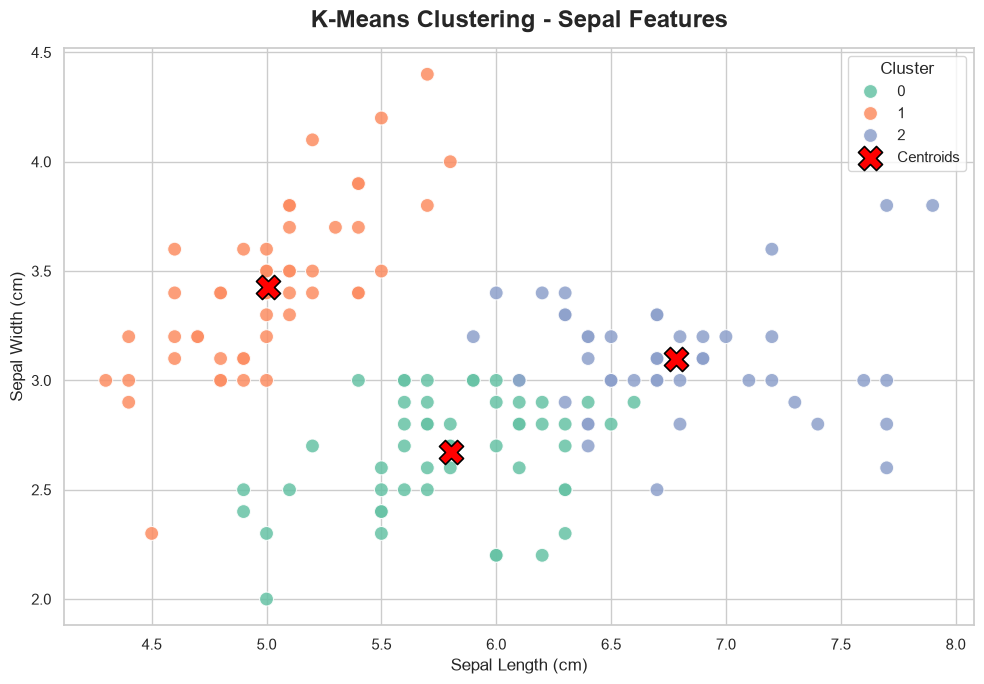

In [15]:
fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="sepal.length",
    y="sepal.width",
    hue="Cluster",
    palette=palette,
    s=100,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.8,
    ax=ax
)

# Plot 3 centroids
ax.scatter(
    centroids_df["sepal.length"],
    centroids_df["sepal.width"],
    color="red",
    marker="X",
    s=300,
    edgecolor="black",
    linewidth=1.2,
    label="Centroids",
    zorder=10
)

ax.set_title(
    "K-Means Clustering - Sepal Features",
    fontsize=17,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Sepal Length (cm)", fontsize=12)
ax.set_ylabel("Sepal Width (cm)", fontsize=12)

ax.legend(title="Cluster", frameon=True)

plt.tight_layout()
plt.show()


# Petal Features Visualization

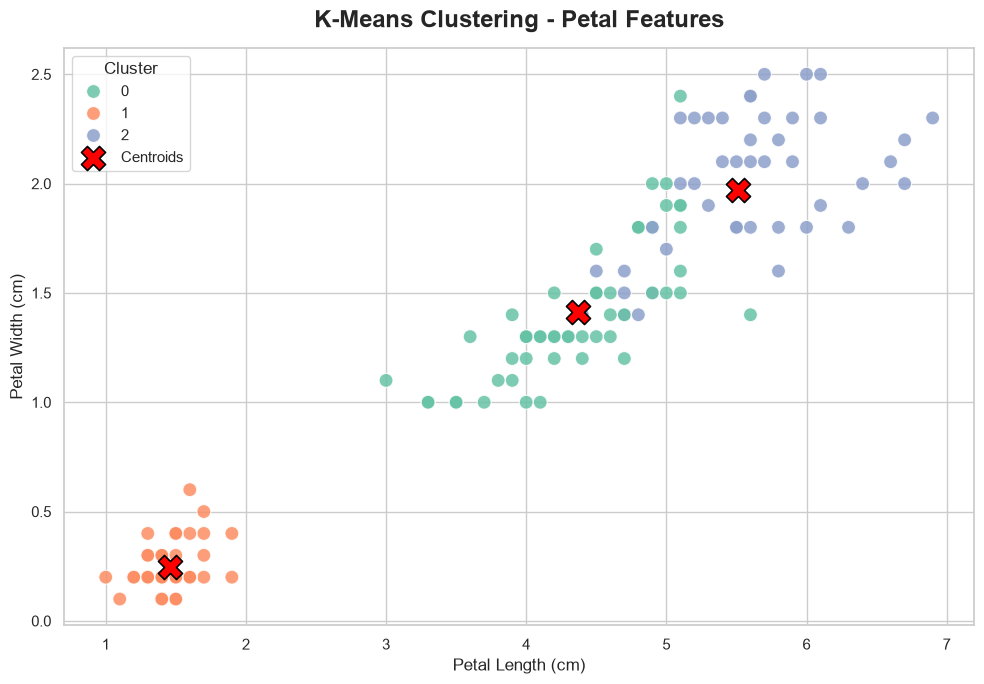

In [16]:

fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="petal.length",
    y="petal.width",
    hue="Cluster",
    palette=palette,
    s=100,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.8,
    ax=ax
)

# Plot 3 centroids
ax.scatter(
    centroids_df["petal.length"],
    centroids_df["petal.width"],
    color="red",
    marker="X",
    s=300,
    edgecolor="black",
    linewidth=1.2,
    label="Centroids",
    zorder=10
)

ax.set_title(
    "K-Means Clustering - Petal Features",
    fontsize=17,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Petal Length (cm)", fontsize=12)
ax.set_ylabel("Petal Width (cm)", fontsize=12)

ax.legend(title="Cluster", frameon=True)

plt.tight_layout()
plt.show()

